# Can Market Regime Detection and Financial News Sentiment Analysis Improve Dynamic Commodity Portfolio Allocation?
### A Machine Learning Approach
**Ons Jdey and Senghak Rou · ENSAE · ML for Portfolio Management and Trading**  
**Submission: 13 November 2026**

## 1. Research question and hypotheses
Commodity markets respond to changing economic conditions, while news may contain information beyond prices. We investigate whether conditioning portfolio allocation on market regimes improves a classical mean–variance benchmark, and whether monthly gold-news sentiment adds value to those regimes.

The first hypothesis is that regime-conditioned moments improve risk-adjusted performance relative to unconditional Markowitz. The two primary sentiment hypotheses are $\Delta SR_{KM}=SR_D-SR_C>0$ and $\Delta SR_{GMM}=SR_F-SR_E>0$. Equal weight provides a simple allocation benchmark.

| ID | Strategy | Regime inputs |
|:--|:--|:--|
| A | Equal weight | None |
| B | Classical Markowitz | None |
| C | KMeans-conditioned Markowitz | Commodity + FRED (21 features) |
| D | KMeans-conditioned Markowitz + sentiment | Commodity + FRED + gold news (22) |
| E | GMM-conditioned Markowitz | Commodity + FRED (21) |
| F | GMM-conditioned Markowitz + sentiment | Commodity + FRED + gold news (22) |

We compare all six strategies on the same news-covered sample. Earlier 2021–2025 project experiments are not pooled with this evaluation.

**Main finding.** Over July 2016–December 2018, sentiment reduces sample Sharpe by 0.168 for KMeans and 0.028 for GMM; both paired 95% intervals include zero. The experiment does not establish an allocation benefit from sentiment. These 30 months were already examined during project development, so the results are a retrospective empirical comparison, not independent confirmation or investable trading performance.

**Reproduction.** Run all cells in Python 3.12 with internet access. All raw inputs are downloaded into memory from immutable public revisions and checked by SHA-256; no API key, local data, other notebook or output file is needed. Saved outputs can be read offline. For the tested environment, run the following in a notebook cell if installation is needed, then restart the kernel:

```python
%pip install numpy==2.4.4 pandas==2.3.3 scipy==1.17.1 scikit-learn==1.9.0 matplotlib==3.10.9 openpyxl==3.1.5 pyarrow==25.0.1 requests==2.34.2 ipython==8.30.0 ipykernel==6.29.5
```

The code stops on download or integrity failure rather than substituting data. Exact numerical replication is checked against the saved project results; other library versions may change fitted clusters.

In [1]:
from io import BytesIO
import requests
from importlib.metadata import version
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from scipy.optimize import minimize, linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", None)
SEED = 42
START, END = pd.Timestamp("2006-04-01"), pd.Timestamp("2018-12-01")
TRAIN_END, MODEL_END = pd.Timestamp("2012-12-01"), pd.Timestamp("2015-12-01")
EVAL_START = pd.Timestamp("2016-07-01")
LOOKBACK, LAG, PRIOR, MIN_EFFECTIVE = 120, 2, 24, 12
GAMMA, CAP, MEAN_SHRINK, COV_SHRINK, FEE_BPS = 5.0, .60, .50, .20, 10
DATASET_ID = "SaguaroCapital/sentiment-analysis-in-commodity-market-gold"
DATASET_REVISION = "4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5"
NAMES = list("ABCDEF")
DESCRIPTIONS = dict(zip(NAMES, ["Equal weight", "Markowitz", "KMeans + FRED",
                              "KMeans + sentiment", "GMM + FRED", "GMM + sentiment"]))
plt.rcParams.update({"font.size": 10, "figure.figsize": (11, 4),
                     "axes.grid": True, "grid.alpha": .2, "grid.linestyle": "-",
                     "lines.linestyle": "-", "lines.linewidth": 1.7,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"A": "#1f77b4", "B": "#ff7f0e", "C": "#9467bd", "D": "#2ca02c",
          "E": "#8c564b", "F": "#e377c2"}
print("Python", sys.version.split()[0])
print({p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn",
                              "matplotlib", "pyarrow", "requests", "openpyxl"]})

Python 3.12.6
{'numpy': '2.4.4', 'pandas': '2.3.3', 'scipy': '1.17.1', 'scikit-learn': '1.9.0', 'matplotlib': '3.10.9', 'pyarrow': '25.0.1', 'requests': '2.34.2', 'openpyxl': '3.1.5'}


## 2. Data and preprocessing
### 2.1 Commodity and macroeconomic sources
The five assets are Brent crude oil (USD/barrel), US natural gas (USD/MMBtu), gold and silver (USD/troy ounce), and copper (USD/metric ton). We reconstruct their monthly average prices directly from the [World Bank Pink Sheet](https://www.worldbank.org/en/research/commodity-markets) workbook, retaining January 2000–December 2018 for warm-up and evaluation. These are nominal benchmark prices, not futures or ETF total returns.

The four daily series are [VIXCLS](https://fred.stlouisfed.org/series/VIXCLS) (CBOE volatility index), [DTWEXBGS](https://fred.stlouisfed.org/series/DTWEXBGS) (broad dollar index), [DGS10](https://fred.stlouisfed.org/series/DGS10) and [DGS2](https://fred.stlouisfed.org/series/DGS2) (Treasury yields, percent). We average valid observations within each calendar month, requiring at least ten days per series. Holidays are not filled with zeros or carried forward.

The market snapshots were retrieved on 7 November 2026 and are preserved at [project revision `3eaa7f3`](https://github.com/onsjd/Machine-learning-for-portfolio-management/tree/3eaa7f398ac0f8cc7ea2d1a89381ad11815a900c/data). Downloading this immutable copy preserves the original source hashes instead of silently adopting later vendor revisions. Original provider URLs remain in the source manifest below.

In [2]:
SNAPSHOT_REVISION = "3eaa7f398ac0f8cc7ea2d1a89381ad11815a900c"
SNAPSHOT_BASE = ("https://raw.githubusercontent.com/onsjd/"
                 f"Machine-learning-for-portfolio-management/{SNAPSHOT_REVISION}/")
MARKET_SOURCES = {'World Bank': {'path': 'data/raw/world_bank_monthly.xlsx',
                'sha256': '3c8d9d8dbb48342fdbf24777c39a8ce8964cc2fd0958f72f6779e6e4ad99cde2',
                'original_url': 'https://thedocs.worldbank.org/en/doc/74e8be41ceb20fa0da750cda2f6b9e4e-0050012026/related/CMO-Historical-Data-Monthly.xlsx'},
 'VIXCLS': {'path': 'data/raw/fred/VIXCLS.csv',
            'sha256': 'b587c3478ee03ccb21a8e5d7582baaa4b921ff6aaef552551f6dd9cb95a81db0',
            'original_url': 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=VIXCLS&cosd=1999-01-01&coed=2025-12-31'},
 'DTWEXBGS': {'path': 'data/raw/fred/DTWEXBGS.csv',
              'sha256': '1569a280c509d0e2e702c0c5fb410415e2c137748a689f430a0116dcb24bc5ed',
              'original_url': 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTWEXBGS&cosd=1999-01-01&coed=2025-12-31'},
 'DGS10': {'path': 'data/raw/fred/DGS10.csv',
           'sha256': '85ffdfe56808d9f340bc267c57c0d578ebae48bc73bc8763c581b891b50cac41',
           'original_url': 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10&cosd=1999-01-01&coed=2025-12-31'},
 'DGS2': {'path': 'data/raw/fred/DGS2.csv',
          'sha256': 'cffee922bb4c42ad21af44f12d453c87afb52f62e6352e4aedcefc89af93ac0a',
          'original_url': 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS2&cosd=1999-01-01&coed=2025-12-31'}}

def download_verified(url, expected_hash):
    try:
        response = requests.get(url, timeout=90)
        response.raise_for_status()
    except requests.RequestException as exc:
        raise RuntimeError(f"Required source unavailable: {url}") from exc
    payload = response.content
    if hashlib.sha256(payload).hexdigest() != expected_hash:
        raise ValueError(f"Source integrity mismatch: {url}")
    return BytesIO(payload)

raw_market = {name: download_verified(SNAPSHOT_BASE + item["path"], item["sha256"])
              for name, item in MARKET_SOURCES.items()}
wb = pd.read_excel(raw_market["World Bank"], sheet_name="Monthly Prices", header=4)
wb = wb.loc[wb.iloc[:, 0].astype(str).str.fullmatch(r"\d{4}M\d{2}")].copy()
wb.index = pd.to_datetime(wb.iloc[:, 0], format="%YM%m")
wb_map = {"Crude oil, Brent": "brent", "Natural gas, US": "natural_gas_us",
          "Gold": "gold", "Silver": "silver", "Copper": "copper"}
prices = wb[list(wb_map)].rename(columns=wb_map).apply(pd.to_numeric).loc["2000-01":END]
prices.index.name = "date"
assert prices.index.equals(pd.date_range("2000-01-01", END, freq="MS"))
assert prices.index.is_unique and np.isfinite(prices).all().all() and prices.gt(0).all().all()

monthly, counts = {}, {}
for sid in ["VIXCLS", "DTWEXBGS", "DGS10", "DGS2"]:
    daily = pd.read_csv(raw_market[sid], index_col=0, parse_dates=True)
    values = pd.to_numeric(daily[sid], errors="coerce").sort_index().loc[:"2018-12-31"]
    assert values.index.is_unique
    counts[sid] = values.resample("MS").count()
    monthly[sid] = values.resample("MS").mean().where(counts[sid] >= 10)
fred = pd.DataFrame(monthly).loc["2000-01":END]
print("Five market source hashes verified; prices and monthly FRED observations reconstructed.")

Five market source hashes verified; prices and monthly FRED observations reconstructed.


### 2.2 Gold-news corpus and cleaning
We use the [SaguaroCapital redistribution](https://huggingface.co/datasets/SaguaroCapital/sentiment-analysis-in-commodity-market-gold/blob/4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5/README.md) of the Sinha–Khandait gold-news corpus, pinned to revision `4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5`. Its card lists **CC BY-NC-ND 4.0**. [Sinha and Khandait (2020)](https://arxiv.org/abs/2009.04202) describe expert annotations of financial headlines; their paper's corpus differs in size from this redistribution. We use the supplied `Price Sentiment` labels, without training a new text classifier or inferring a label-to-direction conversion rule.

The two classification splits are combined before our chronological split. Dates are parsed strictly as day–month–year. We exclude invalid dates, records outside April 2006–December 2018, and empty headlines or labels. A duplicate key is the date plus a lowercased, whitespace-normalized headline. All rows of a key with conflicting annotations are removed; consistent duplicates retain one row. `none` is a valid category, distinct from a missing label. The news cutoff is inherited from the project, not chosen by portfolio performance.

In [3]:
NEWS_HASHES = {
    "train": "65b0f4ab9e6dc2009960b762285924f440f8a551d593a5120905b763c79c1b68",
    "test": "b1a169fea3241630b293391dfe879189221896274d64f2a95fa513633a87f089",
}
news_base = f"https://huggingface.co/datasets/{DATASET_ID}/resolve/{DATASET_REVISION}/data/"
raw_news = pd.concat([
    pd.read_parquet(download_verified(news_base + f"{split}-00000-of-00001.parquet", digest))
      .assign(source_split=split)
    for split, digest in NEWS_HASHES.items()
], ignore_index=True)
LABELS = ["positive", "negative", "neutral", "none"]
BINARY_COLUMNS = ["Price Direction Up", "Price Direction Constant", "Price Direction Down",
                  "Asset Comparision", "Past Information", "Future Information"]
KEYS = ["date", "headline_key"]
def clean_news(raw):
    frame = raw.copy()
    frame["date"] = pd.to_datetime(frame["Dates"].astype("string").str.strip(),
                                    format="%d-%m-%Y", errors="coerce")
    frame["headline"] = frame["News"].astype("string").str.strip()
    frame["label"] = frame["Price Sentiment"].astype("string").str.strip().str.lower()
    frame["headline_key"] = frame["headline"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
    remaining = pd.Series(True, index=frame.index)
    exclusions = {}
    for reason, mask in [
        ("invalid/missing date", frame.date.isna()),
        ("outside window", ~frame.date.between(START, END + pd.offsets.MonthEnd(0))),
        ("empty headline", frame.headline.isna() | frame.headline.eq("")),
        ("empty label", frame.label.isna() | frame.label.eq(""))]:
        removed = remaining & mask.fillna(False)
        exclusions[reason] = int(removed.sum())
        remaining &= ~removed
    candidate = frame.loc[remaining].copy()
    assert candidate.label.isin(LABELS).all()
    assert candidate[BINARY_COLUMNS].isin([0, 1]).all().all()
    conflicts = candidate.groupby(KEYS)[["label"] + BINARY_COLUMNS].nunique(dropna=False).gt(1).any(axis=1)
    bad = pd.MultiIndex.from_frame(candidate[KEYS]).isin(conflicts.index[conflicts])
    consistent = candidate.loc[~bad]
    clean = consistent.drop_duplicates(KEYS).sort_values("date", kind="stable").copy()
    exclusions["conflicting duplicate rows"] = int(bad.sum())
    exclusions["repeated consistent rows"] = len(consistent) - len(clean)
    assert len(raw) == sum(exclusions.values()) + len(clean)
    assert not clean.duplicated(KEYS).any() and not clean.empty
    clean["month"] = clean.date.dt.to_period("M")
    return clean, exclusions


news, news_exclusions = clean_news(raw_news)
assert len(raw_news) == 10570 and len(news) == 9397

### 2.3 Monthly sentiment and coverage
For each observation month $t$, the gold-news feature is
$$S_t=\frac{N_t^+-N_t^-}{N_t^++N_t^-+N_t^{neutral}+N_t^{none}}.$$
This averages scores $+1,-1,0,0$ across all retained headlines. A low balance can reflect offsetting directions or many zero-score headlines. Counts and directional shares are diagnostics, not additional model inputs. An empty month fails validation instead of being assigned neutral sentiment. The aggregate remains indexed by its original month; the information delay is applied at allocation, as specified in Section 3.

In [4]:
def market_features(price_data, macro_data):
    log_returns = np.log(price_data).diff().dropna()
    commodity = pd.concat({"r1": log_returns, "mom3": log_returns.rolling(3).sum(),
                          "vol12": log_returns.rolling(12).std() * np.sqrt(12)}, axis=1).dropna()
    commodity.columns = ["__".join(c) for c in commodity.columns]
    macro = pd.DataFrame({
        "fred_log_vix": np.log(macro_data.VIXCLS),
        "fred_dollar_return_1m": np.log(macro_data.DTWEXBGS).diff(),
        "fred_dollar_momentum_3m": np.log(macro_data.DTWEXBGS).diff(3),
        "fred_yield10_level_pp": macro_data.DGS10,
        "fred_yield10_change_1m_pp": macro_data.DGS10.diff(),
        "fred_yield_slope_10y2y_pp": macro_data.DGS10 - macro_data.DGS2})
    return commodity.join(macro).replace([np.inf, -np.inf], np.nan).dropna()

X_market = market_features(prices, fred).loc[START:END]
ret = prices.pct_change(fill_method=None).dropna()

def aggregate_news(clean):
    months = pd.period_range(START, END, freq="M")
    label_counts = pd.crosstab(clean["month"], clean["label"]).reindex(
        index=months, columns=LABELS, fill_value=0)
    total = label_counts.sum(axis=1)
    assert total.gt(0).all(), "Missing month: do not impute neutral sentiment."
    result = pd.DataFrame({"gold_news_sentiment": (label_counts.positive - label_counts.negative) / total,
                           "gold_news_count": total,
                           "gold_news_directional_share": (label_counts.positive + label_counts.negative) / total})
    result.index = months.to_timestamp(how="start")
    result.index.name = "date"
    return result.asfreq("MS")


monthly_news = aggregate_news(news)
# Independent row-score mean checks the denominator and unshifted month assignment.
row_scores = news.assign(score=news.label.map({"positive": 1, "negative": -1, "neutral": 0, "none": 0}))
row_mean = row_scores.groupby("month").score.mean()
np.testing.assert_allclose(monthly_news.gold_news_sentiment, row_mean.reindex(pd.period_range(START, END, freq="M")))
assert monthly_news.gold_news_count.sum() == len(news)
assert monthly_news.gold_news_sentiment.between(-1, 1).all()
X_sentiment = X_market.join(monthly_news[["gold_news_sentiment"]], validate="one_to_one")
feature_sets = {"market": X_market, "sentiment": X_sentiment}
common = pd.date_range(START, END, freq="MS", name="date")
for data, dimension in [(X_market, 21), (X_sentiment, 22)]:
    assert data.shape == (153, dimension) and data.index.equals(common)
    assert data.index.is_unique and np.isfinite(data.to_numpy()).all()
np.testing.assert_array_equal(X_sentiment.iloc[:, :21], X_market)

In [5]:
quality = pd.DataFrame({
    "Measure": ["Commodity observations", "Aligned feature months", "Downloaded headlines",
                "Invalid dates excluded", "Outside window excluded", "Consistent duplicates removed",
                "Conflicting rows / empty headlines or labels", "Retained headlines", "Headlines per month"],
    "Result": [f"{len(prices)} months × 5 assets; no missing/nonpositive prices",
               f"{len(common)}; 21 / 22 features; no missing months",
               f"{len(raw_news):,}", str(news_exclusions["invalid/missing date"]),
               str(news_exclusions["outside window"]), str(news_exclusions["repeated consistent rows"]),
               f'{news_exclusions["conflicting duplicate rows"]} / '
               f'{news_exclusions["empty headline"] + news_exclusions["empty label"]}',
               f"{len(news):,}",
               f"{monthly_news.gold_news_count.min()}–{monthly_news.gold_news_count.max()} "
               f"(median {monthly_news.gold_news_count.median():.0f})"]
}).set_index("Measure")
display(quality)
assert pd.DataFrame(counts).loc[common].ge(10).all().all()
display(Markdown(f"**News coverage:** {news['Past Information'].mean():.1%} of retained headlines carry a "
    f"past-information flag and {news['Future Information'].mean():.1%} a future-information flag "
    "(flags may overlap). The feature predominantly describes past price statements; changing coverage "
    "and the 165 undatable records limit interpretation."))

,Result
Measure,
Commodity observations,228 months × 5 assets; no missing/nonpositive prices
Aligned feature months,153; 21 / 22 features; no missing months
Downloaded headlines,"10,570"
Invalid dates excluded,165
Outside window excluded,1007
Consistent duplicates removed,1
Conflicting rows / empty headlines or labels,0 / 0
Retained headlines,"9,397"
Headlines per month,14–250 (median 44)


**News coverage:** 96.7% of retained headlines carry a past-information flag and 3.3% a future-information flag (flags may overlap). The feature predominantly describes past price statements; changing coverage and the 165 undatable records limit interpretation.

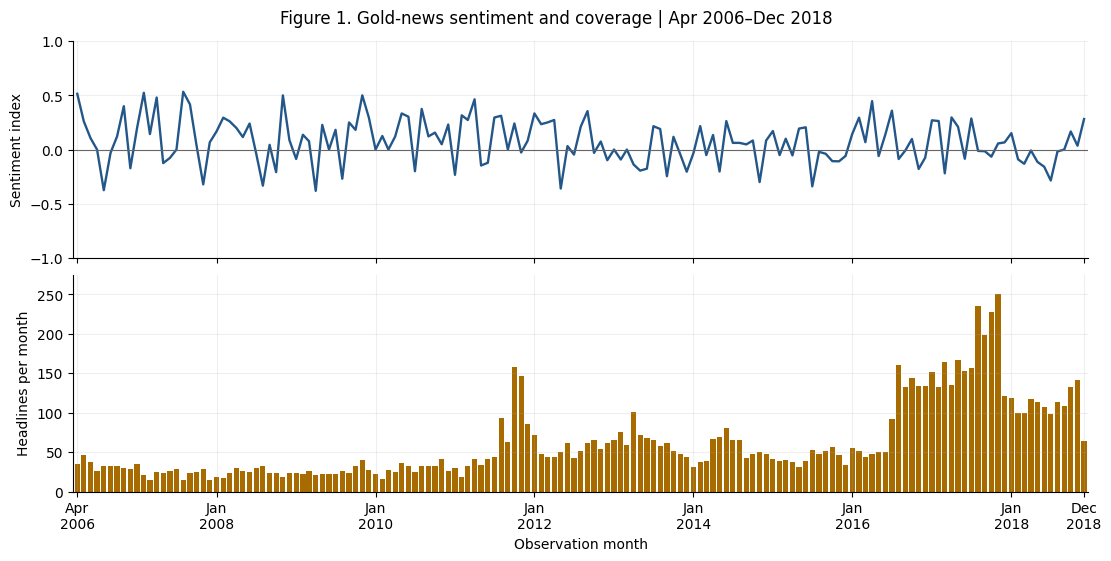

Monthly coverage ranges from 14 to 250 headlines (median 44); sentiment ranges from -0.381 to 0.533. The denominator changes substantially across months. Sparse months are more sensitive to individual headlines, while higher counts need not represent independent information. Counts describe this corpus, not total gold-news activity; coverage alone does not establish a sentiment signal's precision.

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, layout="constrained")
sentiment = monthly_news.gold_news_sentiment
headline_counts = monthly_news.gold_news_count
axes[0].plot(monthly_news.index, sentiment, color="#235789", linestyle="-")
axes[0].axhline(0, color=".4", linewidth=.8, linestyle="-")
axes[0].set(ylabel="Sentiment index", ylim=(-1, 1))
axes[1].bar(monthly_news.index, headline_counts, width=24, color="#A76B00")
axes[1].set(ylabel="Headlines per month", xlabel="Observation month",
            ylim=(0, headline_counts.max()*1.1))
news_ticks = [monthly_news.index[0], *pd.date_range("2008-01-01", "2018-01-01", freq="2YS"),
              monthly_news.index[-1]]
axes[1].set_xticks(news_ticks)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[1].set_xlim(monthly_news.index[0]-pd.Timedelta(days=20),
                 monthly_news.index[-1]+pd.Timedelta(days=20))
fig.suptitle("Figure 1. Gold-news sentiment and coverage | Apr 2006–Dec 2018")
plt.show()
display(Markdown(
    f"Monthly coverage ranges from {headline_counts.min()} to {headline_counts.max()} headlines "
    f"(median {headline_counts.median():.0f}); sentiment ranges from {sentiment.min():.3f} to "
    f"{sentiment.max():.3f}. The denominator changes substantially across months. Sparse months "
    "are more sensitive to individual headlines, while higher counts need not represent independent "
    "information. Counts describe this corpus, not total gold-news activity; coverage alone does not "
    "establish a sentiment signal's precision."))

## 3. Feature engineering and experimental design
### 3.1 Observation-month features
For commodity $i$ and month $t$, define simple price changes $r_{i,t}=P_{i,t}/P_{i,t-1}-1$ for portfolio accounting, and log changes $\ell_{i,t}=\log P_{i,t}-\log P_{i,t-1}$ for regime features. The 15 commodity variables are
$$\ell_{i,t},\qquad m_{i,t}^{(3)}=\sum_{h=0}^{2}\ell_{i,t-h},\qquad
v_{i,t}^{(12)}=\sqrt{12}\,\operatorname{sd}(\ell_{i,t-11},\ldots,\ell_{i,t}),$$
with sample standard deviation. Trailing windows avoid using later observations; overlapping windows also induce persistence.

Six FRED variables complete the market block: log VIX; one- and three-month dollar log changes; the 10-year yield; its one-month change; and the 10y–2y slope. Yields, changes and slopes are in percentage points. 

The vectors $X_t^M\in\mathbb R^{21}$ and $X_t^{M+S}=(X_t^M,S_t)\in\mathbb R^{22}$ are joined on their **unshifted observation month**. No block weighting is added beyond per-feature standardization. The dollar's start and three-month change determine the common start in April 2006.

### 3.2 Chronology and information timing
Training is April 2006–December 2012 (81 months), validation January 2013–December 2015 (36), and final fitting April 2006–December 2015 (117). Scalers use training data during selection and development data during final fitting. Models and scalers are then frozen. Portfolio evaluation is July 2016–December 2018 (30 months), chosen to allow a complete 120-month history of signal–outcome pairs. Earlier 2016 outcomes enter rolling estimates only after the delay.

For an allocation dated $t$, the information cutoff is $c=t-2$. Its current membership is $p_c=p(X_c)$, including $S_c$ for sentiment models. The estimation pairs are
$$\{(p_{u-2},r_u):u=c-119,\ldots,c\}.$$
This applies the same two-month predictor–outcome relationship to historical and current observations. Features are never pre-shifted: **there is no second sentiment lag**. July 2016 uses May 2016 features, returns from June 2006 through May 2016, and historical features from April 2006 through March 2016.

Month-start indices are period labels, not release timestamps. Development memberships are retrospective classifications from the December 2015 fit, which is available before all evaluation decisions. This computational timing does not establish historical availability of the revised inputs or news annotations.

In [7]:
train_dates = common[common <= TRAIN_END]
valid_dates = common[(common > TRAIN_END) & (common <= MODEL_END)]
dev_dates = common[common <= MODEL_END]
test_dates = pd.date_range(EVAL_START, END, freq="MS", name="date")
signal_dates = test_dates - pd.DateOffset(months=LAG)
assert [len(train_dates), len(valid_dates), len(dev_dates), len(test_dates)] == [81, 36, 117, 30]
assert train_dates.max() < valid_dates.min() and dev_dates.max() < signal_dates.min()

def timing_rows(return_data, dates):
    rows = []
    for date in dates:
        cutoff = date - pd.DateOffset(months=LAG)
        history = return_data.loc[:cutoff].tail(LOOKBACK)
        signals = history.index - pd.DateOffset(months=LAG)
        assert history.index.equals(pd.date_range(cutoff - pd.DateOffset(months=LOOKBACK-1), cutoff, freq="MS"))
        assert signals.isin(common).all() and len(history) == LOOKBACK
        assert signals.max() == cutoff - pd.DateOffset(months=LAG)
        assert (signals + pd.DateOffset(months=LAG)).equals(history.index)
        assert MODEL_END < cutoff < date
        rows.append([date, cutoff, history.index.min(), history.index.max(), signals.min(), signals.max()])
    return pd.DataFrame(rows, columns=["allocation", "current signal", "first return", "last return",
                                        "first historical signal", "last historical signal"])
timing = timing_rows(ret, test_dates)
display(timing.iloc[[0, -1]].set_index("allocation").apply(lambda col: col.dt.strftime("%b %Y")))
assert monthly_news.loc[signal_dates[0], "gold_news_sentiment"] == X_sentiment.loc["2016-05-01", "gold_news_sentiment"]

,current signal,first return,last return,first historical signal,last historical signal
allocation,,,,,
2016-07-01,May 2016,Jun 2006,May 2016,Apr 2006,Mar 2016
2018-12-01,Oct 2018,Nov 2008,Oct 2018,Sep 2008,Aug 2018


## 4. Regime detection and portfolio methodology
### 4.1 Regime estimation and model selection
KMeans partitions standardized months by minimizing within-cluster squared distances and gives one-hot membership. Among $k\in\{2,3,4\}$, select the largest validation silhouette; a one-group validation assignment has undefined silhouette. A Gaussian mixture gives posterior component probabilities, allowing different component variances. GMM selects the smallest training BIC, $-2\log L+q\log n$, with diagonal covariances to limit parameters.

Counts are selected using the **21 market features only**, then held fixed in each algorithm's sentiment counterpart. This isolates adding sentiment from changing model capacity. Neither criterion uses evaluation returns or Sharpe. The project settings remain: seed 42; KMeans 30 starts for selection and 50 for refitting; GMM 10 and 20 starts, covariance floor $10^{-4}$ and at most 500 iterations. Standardization prevents different physical units from dominating distances; it does not guarantee equal economic influence of the feature blocks.

In [8]:
def select_counts(market_data):
    train = market_data.loc[train_dates]
    valid = market_data.loc[valid_dates]
    scaler = StandardScaler().fit(train)
    z_train, z_valid = scaler.transform(train), scaler.transform(valid)
    rows = []
    for k in [2, 3, 4]:
        km = KMeans(n_clusters=k, n_init=30, random_state=SEED).fit(z_train)
        gm = GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-4,
                             n_init=10, max_iter=500, random_state=SEED).fit(z_train)
        labels = km.predict(z_valid)
        observed = len(np.unique(labels))
        silhouette = silhouette_score(z_valid, labels) if 1 < observed < len(labels) else np.nan
        assert km.n_iter_ < km.max_iter and gm.converged_
        assert len(np.unique(km.labels_)) == k and np.all(gm.weights_ > 0)
        rows.append({"k": k, "validation silhouette": silhouette, "validation KM groups": observed,
                     "training GMM BIC": gm.bic(z_train), "GMM converged": gm.converged_})
    table = pd.DataFrame(rows).set_index("k")
    assert table["validation silhouette"].notna().any()
    chosen = {"KMeans": int(table["validation silhouette"].idxmax()),
              "GMM": int(table["training GMM BIC"].idxmin())}
    assert scaler.n_samples_seen_ == len(train_dates)
    return chosen, table

selected, selection = select_counts(X_market)
display(selection.round(4))
print("Counts fixed for both feature sets:", selected)

def fit_regimes(data_sets, counts):
    models, probabilities = {}, {}
    for feature_name, data in data_sets.items():
        scaler = StandardScaler().fit(data.loc[dev_dates])
        z_dev = scaler.transform(data.loc[dev_dates])
        for algorithm in ["KMeans", "GMM"]:
            model = (KMeans(n_clusters=counts[algorithm], n_init=50, random_state=SEED)
                     if algorithm == "KMeans" else
                     GaussianMixture(n_components=counts[algorithm], covariance_type="diag", reg_covar=1e-4,
                                     n_init=20, max_iter=500, random_state=SEED))
            model.fit(z_dev)
            assert model.n_iter_ < model.max_iter
            if algorithm == "GMM":
                assert model.converged_ and np.all(model.covariances_ > 0)
            key = {("KMeans", "market"): "C", ("KMeans", "sentiment"): "D",
                   ("GMM", "market"): "E", ("GMM", "sentiment"): "F"}[(algorithm, feature_name)]
            models[key] = {"scaler": scaler, "model": model, "features": feature_name,
                           "fit_end": dev_dates.max(), "algorithm": algorithm}
            z_all = scaler.transform(data)
            p = np.eye(counts[algorithm])[model.predict(z_all)] if algorithm == "KMeans" else model.predict_proba(z_all)
            probabilities[key] = pd.DataFrame(p, index=data.index)
            assert scaler.n_samples_seen_ == len(dev_dates) and np.isfinite(p).all()
            np.testing.assert_allclose(p.sum(axis=1), 1, atol=1e-12)
    return models, probabilities

model_store, probabilities = fit_regimes(feature_sets, selected)
probabilities = {key: probabilities[key] for key in "CDEF"}
labels = pd.DataFrame({key: p.to_numpy().argmax(axis=1) for key, p in probabilities.items()}, index=common)

,validation silhouette,validation KM groups,training GMM BIC,GMM converged
k,,,,
2,0.1617,2,4654.4544,True
3,0.1725,2,4448.1146,True
4,NaN,1,4443.4537,True


Counts fixed for both feature sets: {'KMeans': 3, 'GMM': 4}


### 4.2 Conditional moments, blending and shrinkage
For each decision, use the last 120 monthly outcomes ending at $c$. Classical Markowitz estimates unconditional population moments $(\mu_0,\Sigma_0)$ on that window. Regime $j$ uses weights $a_{u,j}=p_{u-2,j}$, normalized to $q_{u,j}=a_{u,j}/\sum_u a_{u,j}$:
$$\mu_j^*=\sum_u q_{u,j}r_u,\qquad
\Sigma_j^*=\sum_u q_{u,j}(r_u-\mu_j^*)(r_u-\mu_j^*)^\top,\qquad
n_j=\frac{(\sum_u a_{u,j})^2}{\sum_u a_{u,j}^2}.$$
Below 12 effective observations, use unconditional moments. Otherwise blend the component distribution with the unconditional distribution using $\alpha_j=n_j/(n_j+24)$. Blending distributions, rather than only covariances, retains between-mean dispersion. The current memberships then mix the blended component moments:
$$\mu=\sum_j p_{c,j}\mu_j,\qquad
\Sigma=\sum_j p_{c,j}(\Sigma_j+\mu_j\mu_j^\top)-\mu\mu^\top.$$
Both blends use this second-moment identity. Effective-sample blending reduces reliance on sparse regimes. Fixed shrinkage further stabilizes estimation:
$$\widehat\mu=0.5\mu,\qquad
\widehat\Sigma=0.8\Sigma+0.2\operatorname{diag}(\Sigma)+10^{-8}I.$$
These are the project's fixed coefficients, not estimated Ledoit–Wolf shrinkage. B applies the same shrinkage to unconditional moments.

### 4.3 Allocation
B–F solve the same constrained problem by SLSQP:
$$\max_w\left(w^\top\widehat\mu-\frac{5}{2}w^\top\widehat\Sigma w\right),\qquad
\mathbf1^\top w=1,\quad 0\le w_i\le0.60.$$
The risk-aversion coefficient is 5, with no borrowing, shorting or cash allocation. A fixes each weight at 20%. The cap and shrinkage curb concentration and estimation noise. No parameter is selected from evaluation Sharpe ratios. The numerical moment, optimization and accounting functions below retain the original implementation.

In [9]:
def raw_moments(values, weights=None):
    a=np.asarray(values,dtype=float)
    p=np.ones(len(a)) if weights is None else np.asarray(weights,dtype=float)
    p=p/p.sum()
    mu=p@a; centered=a-mu
    cov=(centered*p[:,None]).T@centered
    return mu,cov

def regularize(mu,cov):
    cov=(1-COV_SHRINK)*cov+COV_SHRINK*np.diag(np.diag(cov))
    cov=(cov+cov.T)/2+np.eye(len(mu))*1e-8
    return (1-MEAN_SHRINK)*mu,cov

def optimize(mu,cov,gamma=GAMMA):
    n=len(mu)
    objective=lambda w: gamma/2*(w@cov@w)-w@mu
    gradient=lambda w: gamma*(cov@w)-mu
    result=minimize(objective,np.repeat(1/n,n),jac=gradient,method='SLSQP',
        bounds=[(0,CAP)]*n,constraints={'type':'eq','fun':lambda w:w.sum()-1,
        'jac':lambda w:np.ones(n)},options={'ftol':1e-12,'maxiter':500})
    if not result.success: raise RuntimeError(result.message)
    w=result.x
    assert abs(w.sum()-1)<1e-8 and w.min()>-1e-8 and w.max()<CAP+1e-8
    return w

def blend_moments(mu_a,cov_a,mu_b,cov_b,alpha):
    mu=alpha*mu_a+(1-alpha)*mu_b
    second=alpha*(cov_a+np.outer(mu_a,mu_a))+(1-alpha)*(cov_b+np.outer(mu_b,mu_b))
    return mu,second-np.outer(mu,mu)

In [10]:
def conditional_moments(history,probabilities,cutoff):
    # Outcome u is paired with signal u-2; align by actual calendar month.
    signals=history.index-pd.DateOffset(months=LAG)
    ok=signals.isin(probabilities.index)
    outcomes=history.loc[ok]
    signals=signals[ok]
    prior_mu,prior_cov=raw_moments(history)
    historical_p=probabilities.loc[signals].to_numpy()
    current_p=probabilities.loc[cutoff].to_numpy()
    component_mu=[]; component_cov=[]; effective=[]; fallback=0
    for j in range(historical_p.shape[1]):
        a=historical_p[:,j]; mass=a.sum()
        neff=mass*mass/(a@a) if a@a>0 else 0.0
        effective.append(neff)
        if neff<MIN_EFFECTIVE:
            mu,cov=prior_mu,prior_cov; fallback+=1
        else:
            cm,cc=raw_moments(outcomes,a)
            mu,cov=blend_moments(cm,cc,prior_mu,prior_cov,neff/(neff+PRIOR))
        component_mu.append(mu);component_cov.append(cov)
    means=np.array(component_mu)
    mu=current_p@means
    second=sum(p*(c+np.outer(m,m)) for p,m,c in zip(current_p,means,component_cov))
    cov=second-np.outer(mu,mu)
    return mu,cov,{'effective_current':float(current_p@np.array(effective)),
                  'fallback_components':fallback,'latest_outcome':history.index.max()}

In [11]:
def validate_moments(mu, covariance):
    assert np.isfinite(mu).all() and np.isfinite(covariance).all()
    np.testing.assert_allclose(covariance, covariance.T, rtol=0, atol=1e-12)
    assert np.linalg.eigvalsh(covariance).min() >= -1e-12

def allocate(return_data, probability_tables, dates):
    weight_rows = {key: [] for key in NAMES}
    component_rows = []
    for date in dates:
        cutoff = date - pd.DateOffset(months=LAG)
        history = return_data.loc[:cutoff].tail(LOOKBACK)
        assert len(history) == LOOKBACK and history.index.max() == cutoff and cutoff > MODEL_END
        weight_rows["A"].append(np.repeat(1 / return_data.shape[1], return_data.shape[1]))
        mu, cov = regularize(*raw_moments(history))
        validate_moments(mu, cov)
        weight_rows["B"].append(optimize(mu, cov))
        signals = history.index - pd.DateOffset(months=LAG)
        for key, prob in probability_tables.items():
            assert signals.isin(prob.index).all()  # No shortened conditional window.
            mu, cov, info = conditional_moments(history, prob, cutoff)
            assert info["latest_outcome"] == cutoff
            validate_moments(mu, cov)
            mu, cov = regularize(mu, cov)
            validate_moments(mu, cov)
            weight_rows[key].append(optimize(mu, cov))
            for j in prob.columns:
                a = prob.loc[signals, j].to_numpy()
                n_eff = float(a.sum()**2 / (a @ a)) if (a @ a) > 0 else 0.0
                component_rows.append({"date": date, "strategy": key, "component": j,
                    "ESS": n_eff, "mass": a.sum(), "current_probability": prob.loc[cutoff, j],
                    "fallback": n_eff < MIN_EFFECTIVE,
                    "blend": n_eff/(n_eff+PRIOR) if n_eff >= MIN_EFFECTIVE else 0.0})
    weights = {key: pd.DataFrame(rows, index=dates, columns=return_data.columns)
               for key, rows in weight_rows.items()}
    for table in weights.values():
        assert table.index.equals(dates) and np.isfinite(table).all().all()
        np.testing.assert_allclose(table.sum(axis=1), 1, atol=1e-8)
        assert table.min().min() >= -1e-8 and table.max().max() <= CAP + 1e-8
    return weights, pd.DataFrame(component_rows)

weights, effective_audit = allocate(ret, probabilities, test_dates)

### 4.4 Turnover and transaction costs
Rebalance monthly, allowing the previous holdings to drift with realized price changes. Starting from cash, $TO_1=1$. Turnover counts both purchases and sales, without a factor of one half. At $f=10/10{,}000$ per unit of turnover,
$$TO_t=\sum_i|w_{i,t}-\widetilde w_{i,t}|,\qquad
R_t=(1-fTO_t)(1+w_t^\top r_t)-1,\qquad
\widetilde w_{i,t+1}=\frac{w_{i,t}(1+r_{i,t})}{1+w_t^\top r_t}.$$
Fees are evaluated after allocation; they are not optimized in the objective. This is a common synthetic accounting convention, not an estimate of executable commodity trading costs.

In [12]:
def backtest(weight_table,fee_bps):
    pretrade=np.zeros(ret.shape[1]); rows=[]
    for date,wrow in weight_table.iterrows():
        w=wrow.to_numpy(); r=ret.loc[date].to_numpy()
        turnover=np.abs(w-pretrade).sum()
        gross=float(w@r);cost=fee_bps/10000*turnover
        net=(1-cost)*(1+gross)-1
        rows.append([gross,net,turnover,cost])
        pretrade=w*(1+r)/(1+gross)
    return pd.DataFrame(rows,index=weight_table.index,
                        columns=['gross_return','net_return','turnover','cost_fraction'])

paths = {key: backtest(w, FEE_BPS) for key, w in weights.items()}
net = pd.DataFrame({key: paths[key].net_return for key in NAMES})
gross = pd.DataFrame({key: paths[key].gross_return for key in NAMES})
wealth = (1 + net).cumprod()
initial_date = test_dates[0] - pd.DateOffset(months=1)
wealth_with_start = pd.concat([pd.DataFrame(1., index=[initial_date], columns=NAMES), wealth])
drawdown = wealth_with_start / wealth_with_start.cummax() - 1

## 5. Regime diagnostics
The table reports the selected number of components and hard-assignment counts in component order $0,\ldots,k-1$. Development covers 117 months; evaluation occupancy uses the 30 actual allocation signals (May 2016–October 2018). GMM hard counts use the most probable component only for description; portfolio estimates retain soft memberships.

Persistence is the fraction of adjacent evaluation signals with the same hard label. Stability is the range of adjusted Rand index (ARI) against the main development fit over seeds 0, 7, 21 and 99, with selected counts fixed. ARI is invariant to label permutations. Fallback entries identify components below 12 effective observations and the number of rolling windows concerned. These diagnostics do not select alternative models.

In [13]:
stability_rows = []
for key, entry in model_store.items():
    data = feature_sets[entry["features"]]
    z = entry["scaler"].transform(data.loc[dev_dates])
    for seed in [0, 7, 21, 99]:
        k = selected[entry["algorithm"]]
        alternative = (KMeans(n_clusters=k, n_init=50, random_state=seed) if entry["algorithm"] == "KMeans" else
            GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-4,
                            n_init=20, max_iter=500, random_state=seed))
        alternative.fit(z)
        assert alternative.n_iter_ < alternative.max_iter
        if entry["algorithm"] == "GMM":
            assert alternative.converged_
        stability_rows.append({"strategy": key, "seed": seed,
            "development ARI": adjusted_rand_score(labels.loc[dev_dates, key], alternative.predict(z))})
stability = pd.DataFrame(stability_rows).groupby("strategy")["development ARI"].agg(["min", "median", "max"])


regime_rows = []
for key, p in probabilities.items():
    dev_counts = labels.loc[dev_dates, key].value_counts().reindex(p.columns, fill_value=0)
    eval_counts = labels.loc[signal_dates, key].value_counts().reindex(p.columns, fill_value=0)
    fallback_counts = effective_audit.loc[effective_audit.strategy.eq(key)].groupby("component").fallback.sum()
    y = labels.loc[signal_dates, key]
    assert dev_counts.sum() == len(dev_dates) and eval_counts.sum() == len(signal_dates)
    regime_rows.append({"Strategy": f"{key}: {DESCRIPTIONS[key]}", "k": p.shape[1],
        "Dev. counts": ", ".join(map(str, dev_counts)),
        "Eval. counts": ", ".join(map(str, eval_counts)),
        "Persistence": y.iloc[1:].eq(y.shift(1).iloc[1:]).mean(),
        "Seed ARI": f"{stability.loc[key, 'min']:.3f}–{stability.loc[key, 'max']:.3f}",
        "Fallback (months)": "; ".join(f"{j}: {int(n)}" for j, n in fallback_counts.items() if n) or "None"})
regime_diagnostics = pd.DataFrame(regime_rows).set_index("Strategy")
display(regime_diagnostics.style.format({"Persistence": "{:.1%}"}))

,k,Dev. counts,Eval. counts,Persistence,Seed ARI,Fallback (months)
Strategy,,,,,,
C: KMeans + FRED,3,"62, 51, 4","26, 4, 0",79.3%,0.934–1.000,2: 30
D: KMeans + sentiment,3,"54, 59, 4","6, 24, 0",65.5%,0.871–1.000,2: 30
E: GMM + FRED,4,"12, 53, 12, 40","0, 18, 0, 12",62.1%,0.631–0.810,0: 30
F: GMM + sentiment,4,"12, 52, 41, 12","0, 18, 12, 0",62.1%,0.469–0.811,3: 30


KMeans selects three groups with weak validation separation (silhouette 0.173). Each specification has a four-month development group with no evaluation assignments; its estimator falls back in all 30 windows. Both GMM specifications select four components, two of which have no hard evaluation assignments. Soft probabilities need not be zero, and effective sample size is scale-invariant: tiny membership mass can coexist with nonzero ESS. Fallback uses full-precision ESS.

GMM is especially sensitive to initialization despite convergence. Overlapping rolling features also contribute to persistence. These findings constrain the precision of conditional estimates and the interpretation of clusters as stable economic regimes.

## 6. Portfolio performance and risk
For the common $T=30$ net monthly price-proxy changes,
$$SR=\sqrt{12}\,\bar R/s_R,\qquad \sigma_{ann}=\sqrt{12}\,s_R,\qquad
\mathrm{CAGR}=\left[\prod_t(1+R_t)\right]^{12/T}-1.$$
The risk-free proxy is zero for all strategies. Maximum drawdown includes starting wealth of one; mean turnover includes the initial investment from cash. Strategies remain in the predefined order, without choosing a model by its evaluation ranking.

Wealth compounds the actual net price-proxy changes. Drawdown is $DD_t=W_t/\max_{s\leq t}W_s-1$, including initial wealth $W_0=1$. We retain this percentage drawdown convention from the original portfolio notebooks; the textbook also illustrates additive-PnL and risk-normalized drawdowns. June 2016 marks the initial value, before the 30 evaluation outcomes.

In [14]:
def metrics(returns,turnover):
    vol=returns.std(ddof=1)*np.sqrt(12)
    curve=pd.concat([pd.Series([1.]),(1+returns).cumprod().reset_index(drop=True)],ignore_index=True)
    dd=curve/curve.cummax()-1
    return pd.Series({'CAGR':(1+returns).prod()**(12/len(returns))-1,
        'annualized_vol':vol,'Sharpe_rf0':returns.mean()*12/vol if vol>0 else np.nan,
        'max_drawdown':dd.min(),'mean_monthly_turnover':turnover.mean(),
        'positive_month_fraction':returns.gt(0).mean(),'total_return':(1+returns).prod()-1})

summary = pd.DataFrame({key: metrics(net[key], paths[key].turnover) for key in NAMES}).T
summary["terminal_wealth"] = wealth.iloc[-1]
performance = summary[["Sharpe_rf0", "CAGR", "annualized_vol", "max_drawdown",
                       "mean_monthly_turnover", "terminal_wealth"]].copy()
performance.index = [f"{key}: {DESCRIPTIONS[key]}" for key in NAMES]
performance.columns = ["Sharpe (rf=0)", "CAGR", "Annual volatility", "Max drawdown", "Monthly turnover", "Final wealth"]
display(performance.style.format({"Sharpe (rf=0)": "{:.3f}", "CAGR": "{:.2%}",
    "Annual volatility": "{:.2%}", "Max drawdown": "{:.2%}", "Monthly turnover": "{:.2%}", "Final wealth": "{:.3f}"}))
# Independent metric checks using NumPy and compounded wealth.
np.testing.assert_allclose(summary.Sharpe_rf0, np.sqrt(12)*net.to_numpy().mean(axis=0)/net.to_numpy().std(axis=0, ddof=1))
np.testing.assert_allclose(summary.CAGR, wealth.iloc[-1].to_numpy()**(12/len(test_dates))-1)
np.testing.assert_allclose(summary.max_drawdown, drawdown.min())

,Sharpe (rf=0),CAGR,Annual volatility,Max drawdown,Monthly turnover,Final wealth
A: Equal weight,0.643,8.20%,13.68%,-10.24%,7.30%,1.218
B: Markowitz,0.346,2.82%,9.19%,-11.35%,8.94%,1.072
C: KMeans + FRED,0.681,5.78%,8.81%,-11.16%,18.31%,1.151
D: KMeans + sentiment,0.513,4.39%,9.19%,-11.32%,26.44%,1.114
E: GMM + FRED,0.439,4.42%,11.26%,-9.72%,26.27%,1.114
F: GMM + sentiment,0.410,4.10%,11.30%,-9.69%,27.22%,1.106


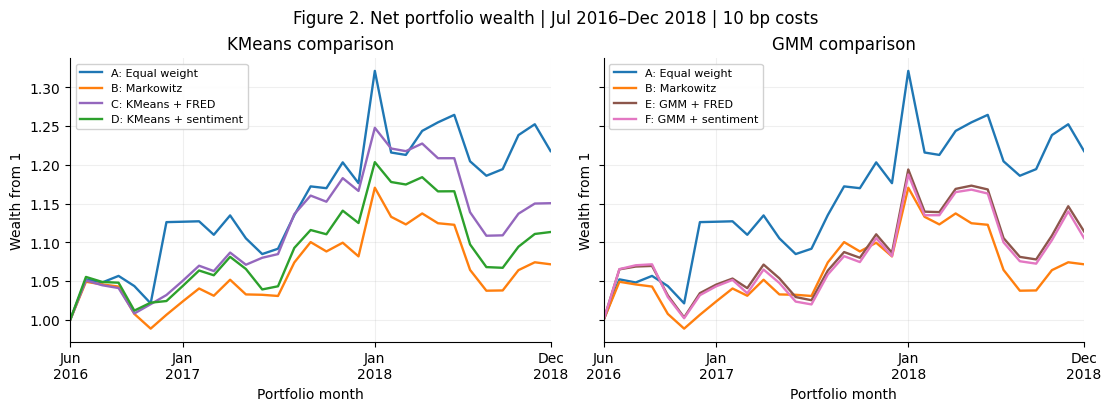

In [15]:
BACKTEST_TICKS = [initial_date, pd.Timestamp("2017-01-01"),
                  pd.Timestamp("2018-01-01"), test_dates[-1]]

def format_backtest_dates(ax):
    ax.set_xlim(initial_date, test_dates[-1])
    ax.set_xticks(BACKTEST_TICKS)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.set_xlabel("Portfolio month")

def plot_portfolio_panels(values, title, ylabel, percentage=False):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True,
                             layout="constrained")
    for ax, keys, panel in zip(axes, ["ABCD", "ABEF"], ["KMeans comparison", "GMM comparison"]):
        for key in keys:
            ax.plot(values.index, values[key], color=COLORS[key], linestyle="-",
                    label=f"{key}: {DESCRIPTIONS[key]}")
        ax.set(title=panel, ylabel=ylabel)
        format_backtest_dates(ax)
        if percentage:
            ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.legend(fontsize=8, loc="best", framealpha=.9)
    fig.suptitle(title)
    return fig, axes

fig, axes = plot_portfolio_panels(wealth_with_start,
    "Figure 2. Net portfolio wealth | Jul 2016–Dec 2018 | 10 bp costs", "Wealth from 1")
plt.show()

In [16]:
display(Markdown(
    f"Classical Markowitz has sample Sharpe **{summary.loc['B', 'Sharpe_rf0']:.3f}**, "
    f"compared with **{summary.loc['A', 'Sharpe_rf0']:.3f}** for equal weight. "
    f"Market-only regime conditioning changes Sharpe relative to Markowitz by "
    f"{summary.loc['C', 'Sharpe_rf0']-summary.loc['B', 'Sharpe_rf0']:+.3f} (KMeans) and "
    f"{summary.loc['E', 'Sharpe_rf0']-summary.loc['B', 'Sharpe_rf0']:+.3f} (GMM). "
    "These are descriptive differences on the same short evaluation sample; "
    "they do not establish reliable gains from regime detection."))

Classical Markowitz has sample Sharpe **0.346**, compared with **0.643** for equal weight. Market-only regime conditioning changes Sharpe relative to Markowitz by +0.335 (KMeans) and +0.092 (GMM). These are descriptive differences on the same short evaluation sample; they do not establish reliable gains from regime detection.

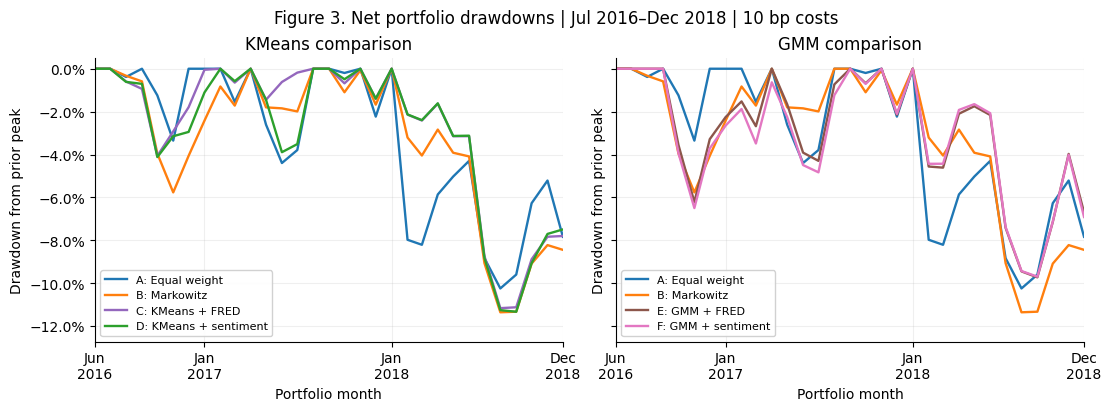

Maximum drawdowns range from -11.35% to -9.69%. Adding sentiment changes maximum drawdown from -11.16% to -11.32% for KMeans and from -9.72% to -9.69% for GMM. The paths reveal losses from earlier peaks that terminal wealth alone does not describe; the small differences between paired strategies do not establish superior downside protection.

In [17]:
# Reuse the net-wealth drawdowns already calculated by the accounting engine.
np.testing.assert_allclose(drawdown, wealth_with_start / wealth_with_start.cummax() - 1)
np.testing.assert_allclose(drawdown.min(), summary.max_drawdown)
fig, axes = plot_portfolio_panels(drawdown,
    "Figure 3. Net portfolio drawdowns | Jul 2016–Dec 2018 | 10 bp costs",
    "Drawdown from prior peak", percentage=True)
for ax in axes:
    ax.set_ylim(drawdown.min().min()*1.12, .005)
plt.show()
display(Markdown(
    f"Maximum drawdowns range from {summary.max_drawdown.min():.2%} to "
    f"{summary.max_drawdown.max():.2%}. Adding sentiment changes maximum drawdown from "
    f"{summary.loc['C', 'max_drawdown']:.2%} to {summary.loc['D', 'max_drawdown']:.2%} for KMeans "
    f"and from {summary.loc['E', 'max_drawdown']:.2%} to {summary.loc['F', 'max_drawdown']:.2%} for GMM. "
    "The paths reveal losses from earlier peaks that terminal wealth alone does not describe; "
    "the small differences between paired strategies do not establish superior downside protection."))

## 7. Incremental sentiment effects and uncertainty
### 7.1 How much does sentiment change allocations?
For each algorithm, compare the two target portfolios on the same allocation date:
$$d_t=\frac12\sum_{i=1}^{5}|w^{sentiment}_{i,t}-w^{baseline}_{i,t}|.$$
This distance lies between zero and one for fully invested long-only portfolios. It measures how much portfolio weight differs **between strategies at the same time**, not trades between successive dates. Trading turnover instead compares a target with that strategy's drifted previous holdings and uses the full absolute difference for fees.

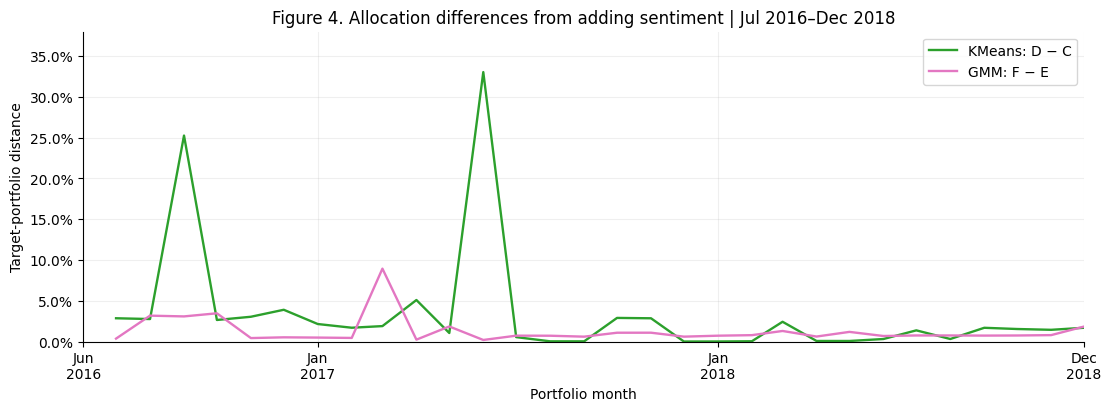

**KMeans: D − C:** mean allocation distance is 3.42%, with a maximum of 33.05% in June 2017. Mean monthly trading turnover changes by +8.13 percentage points.

**GMM: F − E:** mean allocation distance is 1.29%, with a maximum of 8.94% in March 2017. Mean monthly trading turnover changes by +0.96 percentage points.

In [18]:
PAIRS = {"KMeans: D − C": ("D", "C"), "GMM: F − E": ("F", "E")}
allocation_distances = pd.DataFrame({pair: (weights[a]-weights[b]).abs().sum(axis=1)/2
                                   for pair, (a, b) in PAIRS.items()})
assert allocation_distances.index.equals(test_dates)
assert allocation_distances.ge(0).all().all() and allocation_distances.le(1).all().all()
fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
for pair, (a, b) in PAIRS.items():
    ax.plot(allocation_distances.index, allocation_distances[pair],
            color=COLORS[a], linestyle="-", label=pair)
format_backtest_dates(ax)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(ylabel="Target-portfolio distance", ylim=(0, allocation_distances.max().max()*1.15),
       title="Figure 4. Allocation differences from adding sentiment | Jul 2016–Dec 2018")
ax.legend(loc="upper right")
plt.show()
for pair, (a, b) in PAIRS.items():
    distance = allocation_distances[pair]
    display(Markdown(f"**{pair}:** mean allocation distance is {distance.mean():.2%}, "
        f"with a maximum of {distance.max():.2%} in {distance.idxmax():%B %Y}. "
        f"Mean monthly trading turnover changes by "
        f"{100*(paths[a].turnover.mean()-paths[b].turnover.mean()):+.2f} percentage points."))

In [19]:
km_ari = adjusted_rand_score(labels.loc[signal_dates, "C"], labels.loc[signal_dates, "D"])
gm_ari = adjusted_rand_score(labels.loc[signal_dates, "E"], labels.loc[signal_dates, "F"])
overlap = probabilities["E"].loc[dev_dates].to_numpy().T @ probabilities["F"].loc[dev_dates].to_numpy()
row, col = linear_sum_assignment(-overlap)
matched = probabilities["F"].iloc[:, col[np.argsort(row)]].copy()
matched.columns = probabilities["E"].columns
probability_tv = (probabilities["E"].loc[signal_dates]-matched.loc[signal_dates]).abs().sum(axis=1).mean()/2
display(Markdown(f"Adding sentiment changes KMeans evaluation assignments (ARI {km_ari:.3f}) "
    f"more than GMM hard assignments (ARI {gm_ari:.3f}). GMM probabilities still differ "
    f"(mean total-variation distance {probability_tv:.3f}, after matching components on development "
    "data only). Changed regimes and weights therefore do not imply improved performance."))

Adding sentiment changes KMeans evaluation assignments (ARI 0.687) more than GMM hard assignments (ARI 1.000). GMM probabilities still differ (mean total-variation distance 0.027, after matching components on development data only). Changed regimes and weights therefore do not imply improved performance.

### 7.2 Sharpe differences and paired uncertainty
The primary effects are D minus C and F minus E. We retain the paired circular block bootstrap: 1,000 replications, six-month blocks, seed 42. Identical resampled month indices are used for all strategies to preserve pairing and some serial dependence. The 2.5th and 97.5th percentiles give approximate 95% intervals.

Each resample contains only five blocks. The procedure conditions on the observed portfolio paths: it does not refit models, propagate estimation uncertainty or correct for prior examination of the evaluation sample. An interval containing zero is inconclusive, not proof of equivalence.

,Sharpe difference,95% lower,95% upper
KMeans: D − C,-0.1681,-0.6333,0.0619
GMM: F − E,-0.0284,-0.0807,0.0097


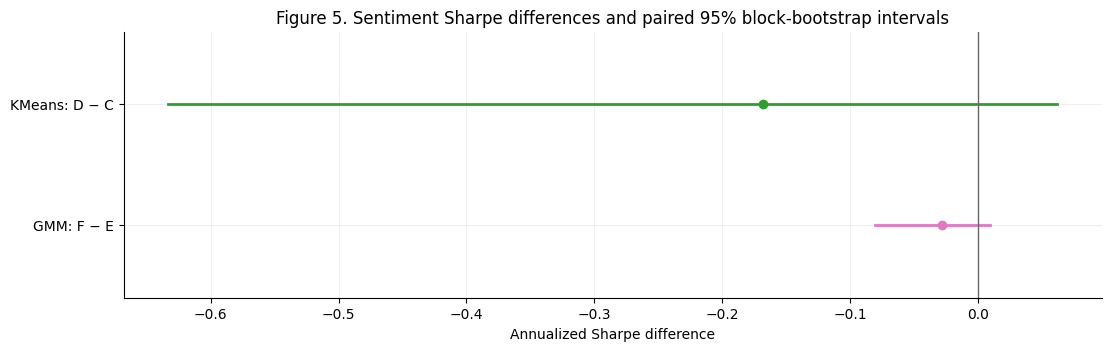

Both point estimates are negative and both intervals include zero. Sentiment changes regimes and allocations without establishing improved risk-adjusted performance. The much smaller GMM point estimate should be read with its uncertainty, not as proof of equivalence.

In [20]:
def paired_bootstrap(returns, block=6, replications=1000):
    rng = np.random.default_rng(SEED)
    n = len(returns)
    boot = []
    for _ in range(replications):
        starts = rng.integers(0, n, size=int(np.ceil(n/block)))
        indices = np.concatenate([(start + np.arange(block)) % n for start in starts])[:n]
        sample = returns.iloc[indices]
        sr = sample.mean()/sample.std(ddof=1)*np.sqrt(12)
        boot.append([sr[a]-sr[b] for a, b in PAIRS.values()])
    samples = np.asarray(boot)
    assert np.isfinite(samples).all()
    observed_sr = returns.mean()/returns.std(ddof=1)*np.sqrt(12)
    result = pd.DataFrame({"Sharpe difference": [observed_sr[a]-observed_sr[b] for a, b in PAIRS.values()],
        "95% lower": np.quantile(samples, .025, axis=0),
        "95% upper": np.quantile(samples, .975, axis=0)}, index=PAIRS)
    return result, samples

primary, bootstrap_samples = paired_bootstrap(net)
for pair, (a, b) in PAIRS.items():
    assert np.isclose(primary.loc[pair, "Sharpe difference"], summary.loc[a, "Sharpe_rf0"]-summary.loc[b, "Sharpe_rf0"])
display(primary.round(4))

fig, ax = plt.subplots(figsize=(11, 3.4), layout="constrained")
for i, (name, row) in enumerate(primary.iterrows()):
    color = COLORS[PAIRS[name][0]]
    ax.plot([row["95% lower"], row["95% upper"]], [i, i],
            color=color, linewidth=2, linestyle="-")
    ax.scatter(row["Sharpe difference"], i, color=color, zorder=3)
ax.axvline(0, color=".4", linewidth=1, linestyle="-")
ax.set_yticks(range(len(primary)), primary.index)
ax.invert_yaxis()
ax.set(xlabel="Annualized Sharpe difference", ylim=(1.6, -.6),
       title="Figure 5. Sentiment Sharpe differences and paired 95% block-bootstrap intervals")
plt.show()
display(Markdown(
    "Both point estimates are negative and both intervals include zero. "
    "Sentiment changes regimes and allocations without establishing improved risk-adjusted performance. "
    "The much smaller GMM point estimate should be read with its uncertainty, not as proof of equivalence."))

## 8. Robustness, limitations and conclusion
### 8.1 Sensitivity and computational checks
The main specification remains fixed. We reprice its weights at 0, 10 and 25 bp and recompute uncertainty with 3-, 6- and 12-month blocks. These are diagnostics, not a parameter search. The code also independently reconstructs cash flows and covariances, checks every information cutoff, and perturbs future returns and memberships to verify that earlier allocations cannot change.

In [21]:
cost_rows = []
for fee in [0, 10, 25]:
    fee_net = pd.DataFrame({key: backtest(weights[key], fee).net_return for key in NAMES})
    sr = fee_net.mean()/fee_net.std(ddof=1)*np.sqrt(12)
    cost_rows.append({"Fee (bp)": fee, **{pair: sr[a]-sr[b] for pair, (a, b) in PAIRS.items()}})
cost_sensitivity = pd.DataFrame(cost_rows).set_index("Fee (bp)")
block_rows = []
for block in [3, 6, 12]:
    estimates = primary if block == 6 else paired_bootstrap(net, block=block)[0]
    block_rows.append(estimates.assign(block_months=block).set_index("block_months", append=True))
block_sensitivity = pd.concat(block_rows)



display(Markdown(
    "Across 0–25 bp, the sentiment Sharpe difference ranges from "
    f"{cost_sensitivity.iloc[:, 0].min():+.3f} to {cost_sensitivity.iloc[:, 0].max():+.3f} for KMeans "
    f"and {cost_sensitivity.iloc[:, 1].min():+.3f} to {cost_sensitivity.iloc[:, 1].max():+.3f} for GMM. "
    "All six intervals at block lengths 3, 6 and 12 include zero. "
    "The negative point estimates are not explained solely by the 10 bp fee assumption."))
assert (block_sensitivity["95% lower"].le(0) & block_sensitivity["95% upper"].ge(0)).all()

Across 0–25 bp, the sentiment Sharpe difference ranges from -0.184 to -0.158 for KMeans and -0.030 to -0.027 for GMM. All six intervals at block lengths 3, 6 and 12 include zero. The negative point estimates are not explained solely by the 10 bp fee assumption.

In [22]:
# Independent vectorized reconstruction checks every monthly cash-flow calculation.
for key, w in weights.items():
    r = ret.loc[test_dates, w.columns]
    independently_gross = (w * r).sum(axis=1)
    drifted = w.mul(1+r).div(1+independently_gross, axis=0).shift(1).fillna(0)
    independently_turnover = (w-drifted).abs().sum(axis=1)
    independently_net = (1-FEE_BPS/10000*independently_turnover)*(1+independently_gross)-1
    np.testing.assert_allclose(paths[key].gross_return, independently_gross, atol=1e-12)
    np.testing.assert_allclose(paths[key].turnover, independently_turnover, atol=1e-12)
    np.testing.assert_allclose(net[key], independently_net, atol=1e-12)
    assert net[key].index.equals(test_dates) and np.isfinite(net[key]).all()
    assert np.isclose(paths[key].turnover.iloc[0], 1)
    assert (net[key] <= gross[key]+1e-12).all()
    np.testing.assert_allclose(backtest(w, 0).net_return, gross[key], atol=1e-12)
    assert (backtest(w, 25).net_return <= net[key]+1e-12).all()

# Every evaluation cutoff: forbidden future values cannot affect the current target.
rng = np.random.default_rng(2026)
max_weight_error = 0.0
for date in test_dates:
    cutoff = date - pd.DateOffset(months=LAG)
    changed_returns = ret.copy()
    future = changed_returns.index > cutoff
    changed_returns.loc[future] = rng.uniform(-.4, .5, size=(future.sum(), ret.shape[1]))
    changed_p = {}
    for key, p in probabilities.items():
        changed_p[key] = p.copy()
        mask = p.index > cutoff
        changed_p[key].loc[mask] = rng.dirichlet(np.ones(p.shape[1]), size=mask.sum())
    replay, _ = allocate(changed_returns, changed_p, pd.DatetimeIndex([date]))
    for key in NAMES:
        error = np.max(np.abs(replay[key].loc[date]-weights[key].loc[date]))
        max_weight_error = max(max_weight_error, error)
        np.testing.assert_allclose(replay[key].loc[date], weights[key].loc[date], rtol=0, atol=1e-10)

# Independent weighted-moment and total-covariance checks on an actual historical window.
history = ret.loc[:signal_dates[0]].tail(LOOKBACK)
a = probabilities["E"].loc[history.index-pd.DateOffset(months=LAG)].iloc[:, 0].to_numpy()
mu, cov = raw_moments(history, a)
np.testing.assert_allclose(mu, np.average(history, axis=0, weights=a))
np.testing.assert_allclose(cov, np.cov(history.to_numpy().T, aweights=a, ddof=0), atol=1e-12)
mu0, cov0 = raw_moments(history)
alpha = .37
mix_mu, mix_cov = blend_moments(mu, cov, mu0, cov0, alpha)
independent_cov = alpha*cov+(1-alpha)*cov0+alpha*(1-alpha)*np.outer(mu-mu0, mu-mu0)
np.testing.assert_allclose(mix_cov, independent_cov, atol=1e-12)

# Frozen source/result fingerprint: a diagnostic, never a model-selection objective.
expected_primary = np.array([[-0.1681, -0.6333, 0.0619], [-0.0284, -0.0807, 0.0097]])
np.testing.assert_allclose(primary.to_numpy(), expected_primary, rtol=0, atol=5e-5)
print("Verified: 7 source hashes; six identical 30-month calendars; 120-month histories; "
      "single two-month signal lag; feasible allocations; covariance identities; drift and fees; "
      "30 future-cutoff perturbations; reproduced primary results.")

Verified: 7 source hashes; six identical 30-month calendars; 120-month histories; single two-month signal lag; feasible allocations; covariance identities; drift and fees; 30 future-cutoff perturbations; reproduced primary results.


### 8.2 Limitations and conclusion
**Historical availability.** The snapshots are revised, not point-in-time vintages. In particular, the Federal Reserve introduced the goods-and-services dollar-index definition underlying DTWEXBGS on 4 February 2019 and backfilled it to January 2006 ([implementation notice](https://www.federalreserve.gov/econres/notes/feds-notes/revisions-to-the-federal-reserve-dollar-indexes-20190115.html)). That definition was unavailable throughout the evaluation period. News dates likewise do not establish contemporaneous collection, annotation or complete monthly coverage. A two-month delay cannot repair these limitations.

**Limited evidence.** Thirty previously examined observations cannot establish persistent gains. Sparse regimes, weak separation, initialization sensitivity and correlated rolling features weaken conditional estimates. The bootstrap has few blocks and excludes model-estimation and research-selection uncertainty. Gold-only sentiment may have little incremental information for the other four assets; its mostly retrospective price statements and uneven news coverage limit a forward-looking interpretation.

**Economic scope.** World Bank monthly-average benchmark-price changes omit executable prices, futures roll yield and collateral returns. The portfolios, drift convention and proportional costs are synthetic. Computational checks establish consistency of this experiment, not historical tradability.

**Answer to the research question.** This comparison does not establish that the specified market regimes and gold-news sentiment improve dynamic commodity allocation. Market-only regimes raise sample Sharpe relative to unconditional Markowitz by 0.335 (KMeans) and 0.092 (GMM), but these are descriptive gains on a short, previously examined sample. Adding sentiment lowers sample Sharpe for both algorithms, with intervals spanning zero. Regime changes and allocation differences are observable, but are not evidence of better forecasts. A stronger assessment would require new evaluation dates, contemporaneously available inputs and investable commodity total returns under a fixed protocol.

### References and implementation attribution
- World Bank, *Commodity Price Data (Pink Sheet)*, and FRED series VIXCLS, DTWEXBGS, DGS10 and DGS2; provider links and immutable download hashes appear in Section 2.
- Sinha, A. and Khandait, T. (2020), [*Impact of News on the Commodity Market: Dataset and Results*](https://arxiv.org/abs/2009.04202); SaguaroCapital's pinned redistribution and licence are cited in Section 2.2.
- von Beschwitz, B., Collins, C. G. and Datta, D. D. (2019), [*Revisions to the Federal Reserve Dollar Indexes*](https://www.federalreserve.gov/econres/notes/feds-notes/revisions-to-the-federal-reserve-dollar-indexes-20190115.html), Federal Reserve Board.
- Champonnois, S. (2026), [*Machine-learning for Portfolio Management and Trading: An Introduction with Scikit-Learn*](https://github.com/schampon/skfin/blob/master/book/book.pdf), Chapters 4 (backtesting), 9 (covariance shrinkage), 15 (transaction costs), 27 (performance and risk metrics) and 30 (empirical research presentation).
- Champonnois, S., [*ML for Portfolio Management and Trading — course notebooks*](https://github.com/schampon/skfin/tree/master/nbs): `10_Mean_variance_estimators`, `11_Backtesting`, `19_Hyperparameter_optimisation`, `30_Transaction_cost`, `41_Timing_backtest_with_learning`, `46_Text_processing` and `92_Project_template`. These inform mean–variance allocation, chronological evaluation, text aggregation and presentation; this project retains its own fixed allocation and cost conventions.
- Jdey, O. and Rou, S., project notebooks 01–05. The commodity/FRED features, seven numerical portfolio functions, news-cleaning rules and final experimental design are reused here. All code needed to reproduce them is included above; the original notebooks are not runtime dependencies.